# SQuADDS Tutorial 5 — a fab-ready 4-qubit chip (USC4Q_qff2024) (Quantcore PDK rebuild)

**What the chip is.** LFL-Lab **SQuADDS**, `tutorials/Tutorial-5_Designing_a_fab_ready_chip_with_SQuADDS.ipynb`
and its GDS `tutorials/gds_files/USC4Q_qff2024.gds`, <https://github.com/LFL-Lab/SQuADDS> — **MIT licence**
("Copyright (c) 2023 Sadman Ahmed Shanto"; notebook footer © Shanto & Levenson-Falk 2024). Depth-1 clone read
2026-11-03 (never executed). Spec: `docs/designs/squadds/tutorial_5_fab_ready_chip.md` (geometry the notebook does
not print was measured from the GDS). Built with Quantum Metal plus SQuADDS' `TransmonCross`.

Four identical grounded cross transmons (one SQuADDS database design: f_q ≈ 3.66 GHz, α ≈ −205 MHz, g ≈ 99 MHz)
on a 5 × 5 mm chip. Each has a λ/4 meander coupled to a straight vertical feedline through a `CoupledLineTee`, and
a charge line ending 50 µm past the cross pocket. The four resonators are "sprayed" over 5.48–8.48 GHz so that one
of them lands on ω₀₂ despite junction spread. Two feedline pads + four charge pads.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | SQuADDS source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 5 × 5 mm chip | the 7.5 × 7.5 mm Quantcore die (`box=(-1250, -1250, 6250, 6250)`: the source's chip area centred in it, so every source coordinate is kept + (2500, 2500) µm), Quantcore die frame, device ID "USC4Q" |
| pads | 2 feedline + 4 charge-line `LaunchpadWirebond`s on the 5 mm chip | the same six launchpads moved to **100 µm** from the die edge (`frame.pad_edge`, `edge="auto"`); the feedline and the charge lines get longer |
| substrate | silicon (the SQuADDS database) | sapphire 650 µm, εr 10.25: the frequencies differ from the source's |
| junctions | Dolan, L_J 15.904 nH (database), f_q target 3.7 GHz | Quantcore trilayer junction **sized for 4.05 GHz** (the PDK band's floor): 0.25 × 0.6 µm, L_J ≈ 13.5 nH, **R_n ≈ 92 kΩ, above the 40–50 kΩ window** (flagged, not retuned) |
| cheese | Metal's GDS-renderer cheese: 25 µm holes on a 125 µm pitch, 100 µm clear of the metal, 200 µm from the chip edge | **the original wins:** the same rule as the chip's `cheese` dict (`metal_cheese_rule(buffer=100, size=25, pitch=125, edge=200)`), drawn by the build instead of the PDK band |
| elements, positions, routes | — | kept: the Metal components with the source's options and positions, the readout lengths, the hanger couplers at the source's centres (`near=`), the charge-line paths |
| placement | centred | centred (checked below) |

**Reproduced (Metal components through the `metal:` wrapper):** `TransmonCross` qubits (cross 210 / 30 / 30 µm, one
claw toward the line, connector at 90°, no claw CPW) at the source positions and orientations; `LaunchpadWirebond`
feedline pads (160 × 80 µm pad, 122 µm taper, 25 µm lead, read from the GDS; feedline 11.7/5.1 µm) and charge-line
pads (150 × 200 µm, 122 µm taper); the readout lengths **including** the tee's coupled part (GDS: 4570 / 3930 / 3460
/ 3100 µm for Q1–Q4); the 325 µm coupled sections with a 7.9 µm ground strip (coupled trace 29.8 µm from the
feedline centre; resonator gap 5.1 µm assumed), shorted; the charge lines with their open ends 284 µm from the qubit
centre (50 µm past the pocket), one corner each (r = 40 µm; the source fillet of 80 µm does not fit the 116 µm leg
of Q2's line in our router).

**Assumed / substituted:** the database row's claw options are not printed in the notebook: claw 190 µm long,
15 µm wide (GDS), `claw_gap` 5.1 µm and `ground_spacing` 9 µm (assumed, so that the claw sits ≈ 39 µm from the cross
as measured in the GDS). Metal's `TransmonCross` stands in for the SQuADDS subclass (same geometry; its Dolan
junction is the Quantcore trilayer junction here). Each `CoupledLineTee` + `RouteMeander` is one qcc λ/4 hanger
route; the meander is KQC's (8 turns, r = 30.9 µm, the source fillet).

The notebook walks through the build step by step: setup and the PDK → die and frame → pads → components →
routes → DRC → netlist → LOM simulation → FEM jobs → results back → one design change → fab export →
snapshots → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import size_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/squadds")                        # design JSON + final snapshots
STEPS = Path("build/snapshots/tutorial_5_fab_ready_chip")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** The source's target f_q (3.7 GHz) is below the PDK band (4–8 GHz), so each
junction is sized for 4.05 GHz, the band's floor, with the qubit's C_Σ from this design's LOM before the rebuild
(95.4 fF without the junction; the database's 15.904 nH + 2 fF gave 3.844 GHz). `size_junction` returns the
trilayer fingers and R_n; `trilayer_junction` gives the cell parameters (`JJ_PARAMS`) and the LOM / FEM junction
values (`JJ`). A 45 kΩ junction would put the qubits at ≈ 5.7 GHz, inside the 5.5–8.5 GHz readout spray, so the
rebuild keeps the 4.05 GHz sizing and the DRC flags its R_n. The targets stay the source's (3.7 GHz).

In [4]:
SIZED = size_junction(4.05, 95.4, c_includes_junction=False)
JJ_PARAMS, JJ = trilayer_junction("metal:TransmonCross", lj_nH=SIZED.lj_nH)
print(JJ, f"R_n {SIZED.rn_kohm:.0f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)

{'Lj_nH': 13.4688, 'Cj_fF': 7.5} R_n 92 kΩ, fingers 0.25 × 0.6 µm; R_n 91.7 kΩ is outside the process window 40–50 kΩ (f_q 4.05 GHz with C_Σ 102.8 fF needs E_J/h 11.9 GHz)


## 3 · The die and its frame

`Designer(...)` starts the chip on the 7.5 × 7.5 mm Quantcore die, with the source's 5 × 5 mm chip area centred in
it: a source point (x, y) (Metal's chip is centred on (0, 0)) sits at (x + `X0`, y + `Y0`) = (x + 2500, y + 2500) µm.
The chip name "USC4Q" is the device ID. The chip `cheese` is the source's own rule: Metal's GDS renderer cheesed
this chip with 25 µm squares on a 125 µm pitch, 100 µm clear of every metal shape and 200 µm from the edge;
`metal_cheese_rule` writes that as a chip `cheese` dict, which the build draws (layout, snapshots, KLive) instead of
the PDK band and `export_fab` / `qcc mask` keep. Its clearance is measured from the 3/0 keep-out, which already
adds the PDK margins, so the holes sit a few µm further from the metal than in the source.

cheese rule: {'size': 25.0, 'gap': 100.0, 'rows': 1000, 'clearance': 100.0, 'edge': 200.0}


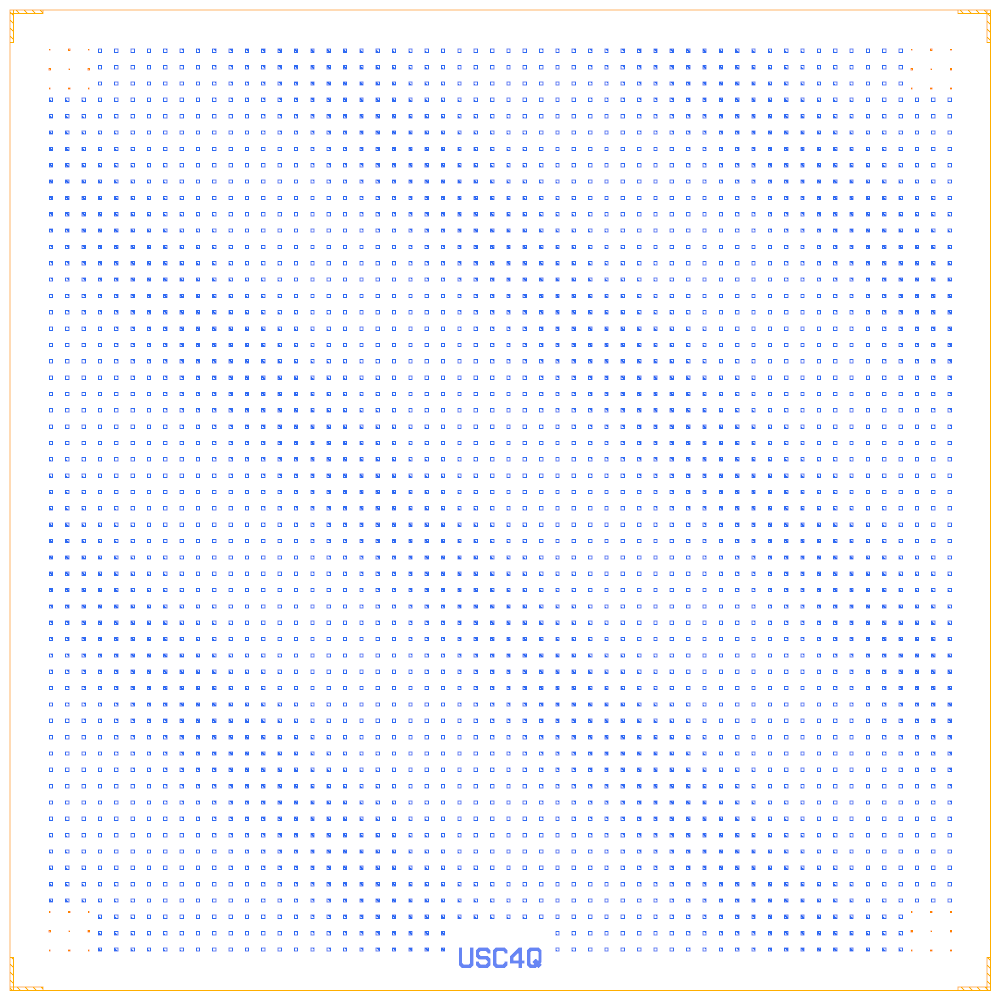

In [5]:
X0, Y0 = 2500, 2500                              # Metal's 5 × 5 mm chip is centred on (0, 0)
CHEESE = metal_cheese_rule(buffer=100, size=25, pitch=125, edge=200)   # the source's renderer cheese
print("cheese rule:", CHEESE)
d = Designer("tutorial_5_fab_ready_chip", box=(-1250, -1250, 6250, 6250),
             chip={"name_chip": "USC4Q", "cheese": CHEESE}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(1000, 1000), width=400);

## 4 · Pads and the pad rule

Six Metal `LaunchpadWirebond`s at the source's positions: the feedline pads P_TOP and P_BOT, and the charge-line
pads LP1–LP4 at (±2000, ±1300) µm. **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge` (100 µm) from
the die edge. `edge="auto"` in `d.add` applies it: each pad keeps its position along its nearest die edge and slides
perpendicular to it until its etch ends 100 µm from that edge. The table measures the result.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_TOP | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P_BOT | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP3 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP4 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

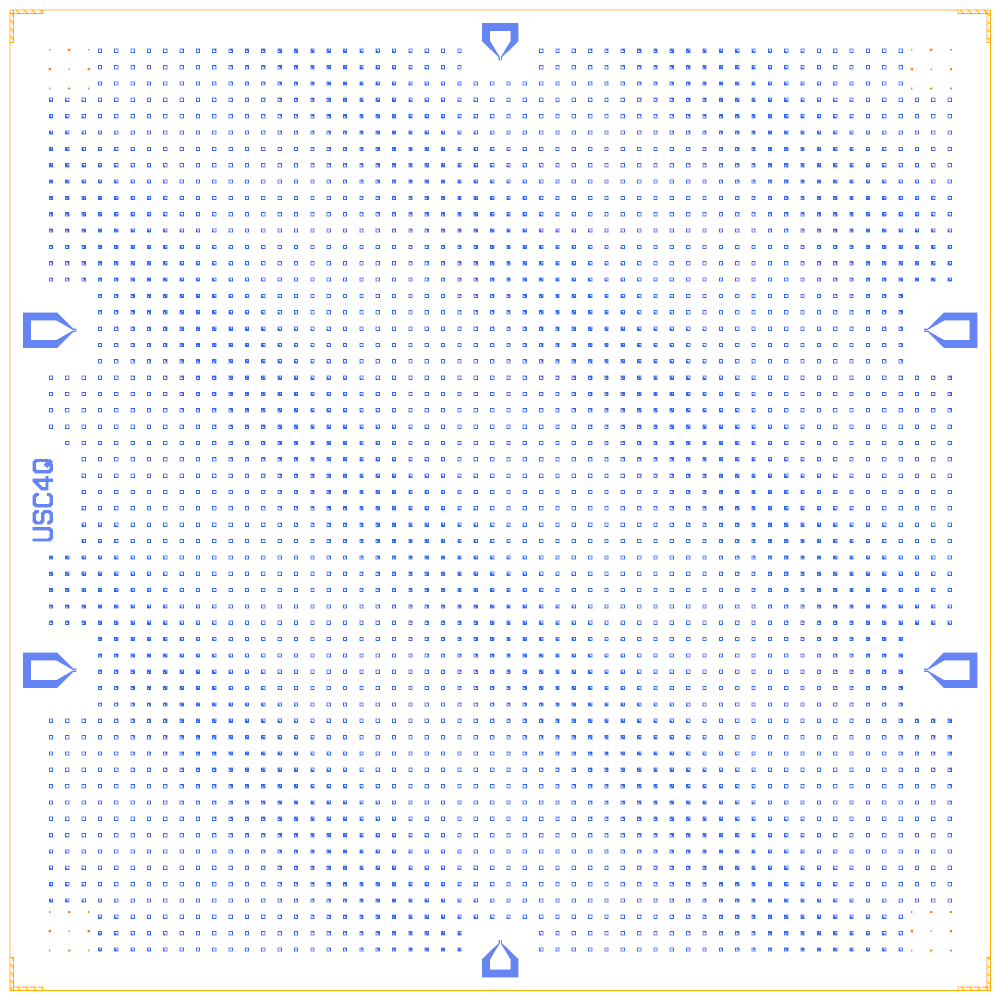

In [6]:
FEED_PAD = dict(trace_width=11.7, trace_gap=5.1, lead_length=25, pad_width=160, pad_height=80, taper_height=122)   # GDS
CL_PAD = dict(trace_width=10, trace_gap=6, lead_length=25, pad_width=150, pad_height=200, taper_height=122)      # GDS
with d.batch():
    top = d.add("P_TOP", "metal:LaunchpadWirebond", at=(X0, Y0 + 2100), rot=-90, edge="auto", **FEED_PAD)
    bot = d.add("P_BOT", "metal:LaunchpadWirebond", at=(X0, Y0 - 1900), rot=90, edge="auto", **FEED_PAD)
    for i, (x, y) in enumerate(((-2000, 1300), (2000, 1300), (-2000, -1300), (2000, -1300)), start=1):
        d.add(f"LP{i}", "metal:LaunchpadWirebond", at=(X0 + x, Y0 + y), rot=0 if x < 0 else 180, edge="auto",
              **CL_PAD)
rebuild(d)                                       # a live=False Designer builds on request: the table reads this build
display(Markdown(pads_md(d)))
snap(d, STEPS / "2_pads.png", size=(1000, 1000), width=400);

**Here:** all six pads end 100.0 µm from their die edge: P_TOP moved 1290 µm up, P_BOT 1490 µm down and the four charge pads 1270 µm out (west / east). The feedline is 2780 µm longer (6730 µm) and each charge line 1270 µm longer.

## 5 · Components

Four Metal `TransmonCross` qubits through the `metal:` wrapper (bare numbers on length options are µm): a 210 µm
cross with 30 µm arms in a 30 µm gap, one claw (`connection_pads` "c") facing the feedline — 190 × 15 µm, 5.1 µm
gap, 9 µm ground spacing, at 90° — and the trilayer junction from step 2. The west qubits (Q1, Q3) are rotated −90°,
the east ones (Q2, Q4) +90°, as in the source. Port `c` is the claw's connector; `squid_a` / `squid_b` are the
junction's attachment points (the qubit draws its own junction).

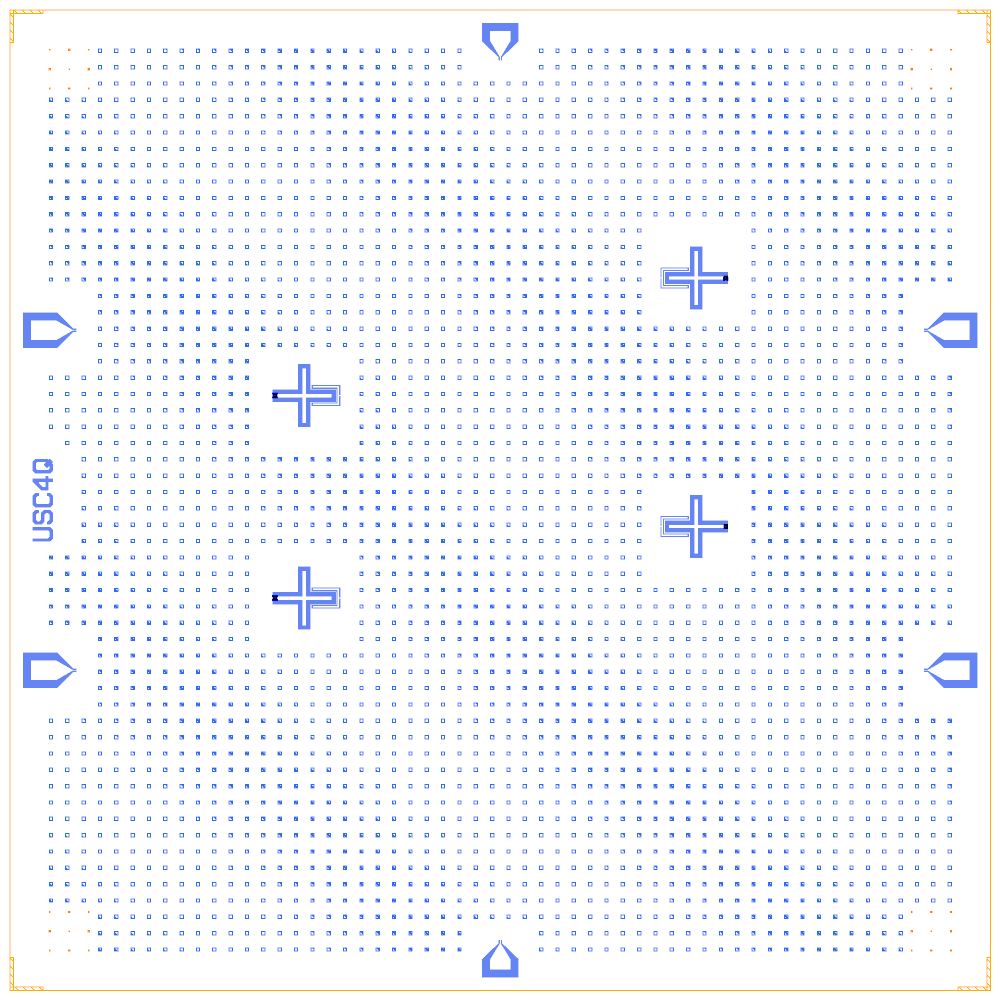

In [7]:
CLAW = dict(connector_location="90", connector_type="0", claw_length=190, claw_width=15, claw_gap=5.1,
            ground_spacing=9, claw_cpw_length=0)                     # claw_gap / ground_spacing assumed
CROSS = dict(cross_length=210, cross_width=30, cross_gap=30, connection_pads={"c": CLAW})
# name, source (x, y), coupler centre s from P_TOP's source tie, direction, readout length (GDS, incl. tee), f target
QUBITS = (("Q1", (-1500, 800), 1262.5, "backward", 4570, 5.48), ("Q2", (1500, 1700), 387.5, "forward", 3930, 6.48),
          ("Q3", (-1500, -750), 2812.5, "backward", 3460, 7.48), ("Q4", (1500, -200), 2287.5, "forward", 3100, 8.48))
with d.batch():
    for name, (x, y), *_ in QUBITS:
        d.add(name, "metal:TransmonCross", at=(X0 + x, Y0 + y), rot=-90 if x < 0 else 90, junction=JJ, **JJ_PARAMS,
              **CROSS)
snap(d, STEPS / "3_components.png", size=(1000, 1000), width=400);

## 6 · Routes

**The feedline** `FL` runs straight down from P_TOP's tie to P_BOT's (11.7/5.1 µm). **The readouts** are λ/4 hanger
routes from each claw: an 8-turn meander (r = 30.9 µm) and a 325 µm coupled section with a 7.9 µm ground strip,
shorted at its far end. The source places each coupler by its arclength `s` from P_TOP's tie; the pad rule moves
P_TOP 1290 µm up, which would slide every coupler, so the rebuild anchors each one by position instead:
`fl.hanger(near=(X0, Y_TIE − s), ...)` centres it at the feedline point nearest the source's coupler centre (Y_TIE
= 4575 µm, P_TOP's tie at the source position). `direction` sets which end is shorted. **The charge lines** run
from each LP pad along the pad's y, turn once (r = 40 µm) and end open 284 µm from the qubit centre.

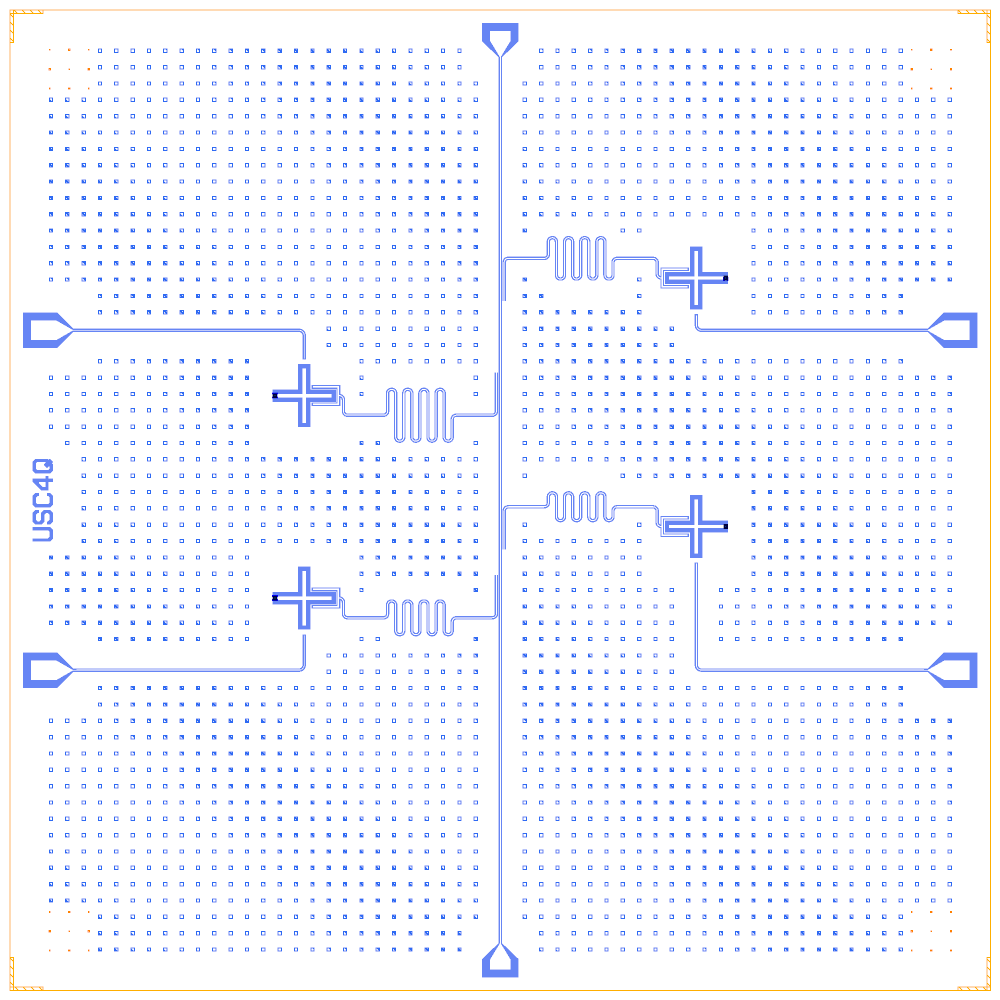

{'FL': 6730.0, 'R1': 4570.0, 'CL1': 1943.8, 'R2': 3930.0, 'CL2': 1843.8, 'R3': 3460.0, 'CL3': 1993.8, 'R4': 3100.0, 'CL4': 2543.8}


In [8]:
Y_TIE = Y0 + 2075                                # P_TOP's tie at the source position (y = 4575 µm)
with d.batch():
    fl = d.route("FL", top.tie, bot.tie, a=11.7, b=5.1)
    for i, (name, (x, y), s, way, L, f) in enumerate(QUBITS, start=1):
        west = x < 0
        d.route(f"R{i}", f"{name}.c", fl.hanger(near=(X0, Y_TIE - s), length=325, side="right" if west else "left",
                                                ground_gap=7.9, direction=way, end="short"),
                meander=L, a=11.7, b=5.1, r=30.9).set(meanders=8)
        py = Y0 + (1300 if y > 0 else -1300)        # the charge pad's row
        below = py < Y0 + y                         # pad row below the qubit: the line comes up from below
        tip = (X0 + x, Y0 + y + (-284 if below else 284))
        d.route(f"CL{i}", f"LP{i}.tie", Designer.free_end(tip, dir=270 if below else 90, term=6), nodes=[(X0 + x, py)],
                r=40)
snap(d, STEPS / "4_routes.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

**Targets, sim groups, centring, save.** The targets are the source's (f_q 3.7 GHz, α −210 MHz, f_r 5.48–8.48
GHz). One sim group per qubit with its readout, the feedline and its charge line (Q3D C-matrix and eigenmode).
`center_in_die` checks that the content sits centred in the die and shifts it if it is more than 50 µm off. Then
the design is saved.

In [9]:
for i, (name, _, _, _, _, f) in enumerate(QUBITS, start=1):
    d.targets(**{name: {"f_q_GHz": 3.7, "alpha_MHz": -210}, f"R{i}": {"f_GHz": f}})
    d.sim_group(f"{name}R{i}", [name, f"R{i}", "FL", f"CL{i}"], analyses=["q3d_cmatrix", "eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "tutorial_5_fab_ready_chip.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer tutorial_5_fab_ready_chip: 10 instances, 9 routes, live=False> → examples\designs\squadds\tutorial_5_fab_ready_chip.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** 0 errors, 8 `dangling_port` warnings (each `TransmonCross`'s `squid_a` / `squid_b`: the qubit draws its own junction) and **8 PDK design warnings**: `pdk_rn` × 4 (R_n 90 kΩ from the 4.05 GHz sizing, above 40–50 kΩ) and `pdk_fq` × 4 (the source's 3.7 GHz target is below the 4–8 GHz band). They are flagged, not retuned. No `pad_edge`: the pads are at 100 µm. `pdk_report` gives the original's cheese rule drawn in the build, the content centred (0, 0) and "Quantcore Junction × 4".

In [10]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 8 warnings · 8 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 8 | Q1.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_fq` | 4 | Q1: f_q target 3.7 GHz is outside the PDK band 4–8 GHz |
| PDK design warning | `pdk_rn` | 4 | Q1: junction R_n 90.0 kΩ is outside the PDK window 40–50 kΩ (L_J 13.4688 nH) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 100, rows 1000, clearance 100, edge 200 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4 |
| PDK design warnings | 8 (pdk_rn × 4, pdk_fq × 4) |
| pdk_rn | Q1: junction R_n 90.0 kΩ is outside the PDK window 40–50 kΩ (L_J 13.4688 nH) |
| pdk_rn | Q2: junction R_n 90.0 kΩ is outside the PDK window 40–50 kΩ (L_J 13.4688 nH) |
| pdk_rn | Q3: junction R_n 90.0 kΩ is outside the PDK window 40–50 kΩ (L_J 13.4688 nH) |
| pdk_rn | Q4: junction R_n 90.0 kΩ is outside the PDK window 40–50 kΩ (L_J 13.4688 nH) |
| pdk_fq | Q1: f_q target 3.7 GHz is outside the PDK band 4–8 GHz |
| pdk_fq | Q2: f_q target 3.7 GHz is outside the PDK band 4–8 GHz |
| pdk_fq | Q3: f_q target 3.7 GHz is outside the PDK band 4–8 GHz |
| pdk_fq | Q4: f_q target 3.7 GHz is outside the PDK band 4–8 GHz |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `TransmonCross` is a cross node (C to ground, the junction
to ground) and a claw node (C_g to the cross, C to ground); each readout route is a λ/4 `TLres` from the claw node,
shorted at the coupled section's far end, coupled to the feedline node by the hanger; the feedline runs between the
two 50 Ω feedline pads. The charge lines end open near the qubits: the LOM makes each a λ/2 line on its 50 Ω pad,
with no coupling to the qubit (no drive control).

In [11]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("Q1."))))

**14 nodes · 34 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `P_TOP.pad`, `P_BOT.pad` |
| `LP1.pad` | `LP1.pad` |
| `LP2.pad` | `LP2.pad` |
| `LP3.pad` | `LP3.pad` |
| `LP4.pad` | `LP4.pad` |
| `Q1` | `Q1.island` |
| `Q1.c` | `Q1.c` |
| `Q2` | `Q2.island` |
| `Q2.c` | `Q2.c` |
| `Q3` | `Q3.island` |
| `Q3.c` | `Q3.c` |
| `Q4` | `Q4.island` |
| `Q4.c` | `Q4.c` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_TOP` | R | `FL` – `gnd` | 50 Ω |
| `Port_P_BOT` | R | `FL` – `gnd` | 50 Ω |
| `Port_LP1` | R | `LP1.pad` – `gnd` | 50 Ω |
| `Port_LP2` | R | `LP2.pad` – `gnd` | 50 Ω |
| `Port_LP3` | R | `LP3.pad` – `gnd` | 50 Ω |
| `Port_LP4` | R | `LP4.pad` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 90.2 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 13.5 nH, Cj 7.5 fF |
| `Cg_Q1_c` | C | `Q1` – `Q1.c` | 4.6 fF |
| `Cc_Q1_c` | C | `Q1.c` – `gnd` | 91.8 fF |
| `C_Q2` | C | `Q2` – `gnd` | 90.2 fF |
| `J_Q2` | JJ | `Q2` – `gnd` | Lj 13.5 nH, Cj 7.5 fF |
| `Cg_Q2_c` | C | `Q2` – `Q2.c` | 4.6 fF |
| `Cc_Q2_c` | C | `Q2.c` – `gnd` | 91.8 fF |
| `C_Q3` | C | `Q3` – `gnd` | 90.2 fF |
| `J_Q3` | JJ | `Q3` – `gnd` | Lj 13.5 nH, Cj 7.5 fF |
| `Cg_Q3_c` | C | `Q3` – `Q3.c` | 4.6 fF |
| `Cc_Q3_c` | C | `Q3.c` – `gnd` | 91.8 fF |
| `C_Q4` | C | `Q4` – `gnd` | 90.2 fF |
| `J_Q4` | JJ | `Q4` – `gnd` | Lj 13.5 nH, Cj 7.5 fF |
| `Cg_Q4_c` | C | `Q4` – `Q4.c` | 4.6 fF |
| `Cc_Q4_c` | C | `Q4.c` – `gnd` | 91.8 fF |
| `R1` | TLres | `Q1.c` – `gnd` | lambda/4, 4570 µm, 6.908 GHz |
| `K_R1` | HANGER | `Q1.c` – `FL` | κ 0.164 MHz (L 325 µm) |
| `CL1` | TLres | `LP1.pad` – `gnd` | lambda/2, 1944 µm, 32.419 GHz |
| `R2` | TLres | `Q2.c` – `gnd` | lambda/4, 3930 µm, 8.033 GHz |
| `K_R2` | HANGER | `Q2.c` – `FL` | κ 0.258 MHz (L 325 µm) |
| `CL2` | TLres | `LP2.pad` – `gnd` | lambda/2, 1844 µm, 34.177 GHz |
| `R3` | TLres | `Q3.c` – `gnd` | lambda/4, 3460 µm, 9.125 GHz |
| `K_R3` | HANGER | `Q3.c` – `FL` | κ 0.377 MHz (L 325 µm) |
| `CL3` | TLres | `LP3.pad` – `gnd` | lambda/2, 1994 µm, 31.606 GHz |
| `R4` | TLres | `Q4.c` – `gnd` | lambda/4, 3100 µm, 10.184 GHz |
| `K_R4` | HANGER | `Q4.c` – `FL` | κ 0.524 MHz (L 325 µm) |
| `CL4` | TLres | `LP4.pad` – `gnd` | lambda/2, 2544 µm, 24.773 GHz |

**Unconnected ports:** none

**Q1's ports → circuit nodes:**

| port | node |
|---|---|
| `Q1.c` | `Q1.c` |
| `Q1.squid_a` | `Q1` |
| `Q1.squid_b` | `gnd` |

## 9 · LOM simulation

Each qubit with its readout and the whole feedline: QuCat's normal modes and the QuTiP-dressed f_q, α, f_r, κ, χ,
against the source's targets (the brackets: f_q 3.7 GHz, α −210 MHz, the sprayed readouts 5.48–8.48 GHz, all on
silicon in the source).

In [12]:
targets = {**{q[0]: {"f_q_GHz": 3.7, "alpha_MHz": -210} for q in QUBITS},
           **{f"R{i}": {"f_GHz": q[5]} for i, q in enumerate(QUBITS, start=1)}}
groups = {f"{q[0]}R{i}": [q[0], f"R{i}", "FL"] for i, q in enumerate(QUBITS, start=1)}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res, targets)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1R1 | Q1 | 4.088 (3.7) | -212.8 (-210) | R1 | 6.1191 (5.48) | 0.101 | -0.381 |
| Q2R2 | Q2 | 4.0882 (3.7) | -212.9 (-210) | R2 | 6.9934 (6.48) | 0.148 | -0.275 |
| Q3R3 | Q3 | 4.0883 (3.7) | -213 (-210) | R3 | 7.8156 (7.48) | 0.203 | -0.228 |
| Q4R4 | Q4 | 4.0884 (3.7) | -213 (-210) | R4 | 8.5912 (8.48) | 0.265 | -0.204 |

**Here:** f_q 4.088 GHz for all four (the 4.05 GHz sizing plus the claw loading; target 3.7 GHz on silicon), α ≈ −213 MHz (target −210 MHz); f_r 6.12 / 6.99 / 7.82 / 8.59 GHz (targets 5.48 / 6.48 / 7.48 / 8.48 GHz: sapphire's lower εr raises every λ/4), κ 0.10–0.27 MHz, χ −0.38 … −0.20 MHz.

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one Q3D C-matrix and one eigenmode job per qubit with its readout, the feedline and its charge line.

In [13]:
jobs = send_fem_jobs(DESIGN, analyses=["q3d_cmatrix", "eigenmode_epr"], run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

8 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 · q3d_cmatrix | `build/jobs/tutorial_5_fab_ready_chip_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.c`<br>3 · lumped · `LP1.pad`<br>4 · lumped · `P_BOT.pad`<br>5 · lumped · `P_TOP.pad` | `Q1.island`, `Q1.c`, `P_BOT.pad`, `CL3` |
| Q1R1 · eigenmode_epr | `build/jobs/tutorial_5_fab_ready_chip_Q1R1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · lumped · `LP1.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q1.island`, `LP1.pad`, `P_BOT.pad`, `CL3` |
| Q2R2 · q3d_cmatrix | `build/jobs/tutorial_5_fab_ready_chip_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.c`<br>3 · lumped · `LP2.pad`<br>4 · lumped · `P_BOT.pad`<br>5 · lumped · `P_TOP.pad` | `Q2.island`, `Q2.c`, `P_BOT.pad`, `CL4` |
| Q2R2 · eigenmode_epr | `build/jobs/tutorial_5_fab_ready_chip_Q2R2_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · lumped · `LP2.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q2.island`, `LP2.pad`, `P_BOT.pad`, `CL4` |
| Q3R3 · q3d_cmatrix | `build/jobs/tutorial_5_fab_ready_chip_Q3R3_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.c`<br>3 · lumped · `LP3.pad`<br>4 · lumped · `P_BOT.pad`<br>5 · lumped · `P_TOP.pad` | `Q3.island`, `Q3.c`, `P_BOT.pad`, `CL1` |
| Q3R3 · eigenmode_epr | `build/jobs/tutorial_5_fab_ready_chip_Q3R3_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · lumped · `LP3.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q3.island`, `LP3.pad`, `P_BOT.pad`, `CL1` |
| Q4R4 · q3d_cmatrix | `build/jobs/tutorial_5_fab_ready_chip_Q4R4_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.c`<br>3 · lumped · `LP4.pad`<br>4 · lumped · `P_BOT.pad`<br>5 · lumped · `P_TOP.pad` | `Q4.island`, `Q4.c`, `P_BOT.pad`, `CL2` |
| Q4R4 · eigenmode_epr | `build/jobs/tutorial_5_fab_ready_chip_Q4R4_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · lumped · `LP4.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q4.island`, `LP4.pad`, `P_BOT.pad`, `CL2` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [14]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for Q1R1 · q3d_cmatrix, Q1R1 · eigenmode_epr, Q2R2 · q3d_cmatrix, Q2R2 · eigenmode_epr, Q3R3 · q3d_cmatrix, Q3R3 · eigenmode_epr, Q4R4 · q3d_cmatrix, Q4R4 · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The readout spray is set by the λ/4 lengths. Shorten R1 from 4570 to 4400 µm: its f_r rises (≈ +4 %), further
from the qubit, so |χ| drops; f_q and α barely move. The change is made on a copy (`design_copy`), so
`tutorial_5_fab_ready_chip.json` keeps the source's 4570 µm.

In [15]:
d2 = design_copy(DESIGN)
d2["R1"].set(meander=4400)
after = simulate_groups(d2, {"Q1R1": groups["Q1R1"]})
display(Markdown("**R1: 4570 → 4400 µm**\n\n" + params_delta_md({"Q1R1": res["Q1R1"]}, after)))

**R1: 4570 → 4400 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1R1: Q1.f_q_GHz` | 4.088 | 4.088 | +6.299e-05 |
| `Q1R1: Q1.alpha_MHz` | -212.82 | -212.85 | -0.03606 |
| `Q1R1: R1.chi_MHz` | -0.38093 | -0.34594 | +0.03499 |
| `Q1R1: R1.f_GHz` | 6.1191 | 6.3291 | +0.21 |
| `Q1R1: R1.kappa_MHz` | 0.10106 | 0.11133 | +0.01028 |

**Result.** R1's f_r moves from 6.119 to 6.329 GHz (+210 MHz), |χ| drops from 0.381 to 0.346 MHz and κ rises from 0.101 to 0.111 MHz; f_q and α do not move (< 0.1 MHz).

## 13 · Build and export

**The design file.** `tutorial_5_fab_ready_chip.json` (saved in step 6) is the whole design: `qcc build
examples/designs/squadds/tutorial_5_fab_ready_chip.json` rebuilds `build/tutorial_5_fab_ready_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: the source's own rule drawn in the build (25 µm holes on a 125 µm pitch,
100 µm from 3/0, 200 µm from the die edge), and no PDK band is added. In this run: 1/0 2542 polygons, 3/0 2534 (the keep-outs plus the holes), 2524 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/squadds/tutorial_5_fab_ready_chip.json` writes the complete file.

In [16]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 2542 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 2534 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 2524 holes on the mask.

→ `build/tutorial_5_fab_ready_chip_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [17]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'} 1 conductor(s) no port or LOM node touches, named after their component: CL3 (cut where dropped airbridges crossed, floating parts of a cell, or ground enclosed by it; airbridges=True keeps the bridges)


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'} 1 conductor(s) no port or LOM node touches, named after their component: CL3 (cut where dropped airbridges crossed, floating parts of a cell, or ground enclosed by it; airbridges=True keeps the bridges)


## 14 · Snapshots

The full chip (the six pads at the die edges, the source's cheese over the free ground, the frame); qubit Q1 with
its claw and charge-line end; its junction; the R1 coupled section on the feedline; the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and Q1 in the **fab view** (the mask from step 13: 1/0
with the cheese holes, 3/0, the trilayer junction layers). The chip boundary 100/0 is drawn as an outline. The
source's GDS is not in this checkout, so it is not shown; compare the tutorial's own picture.

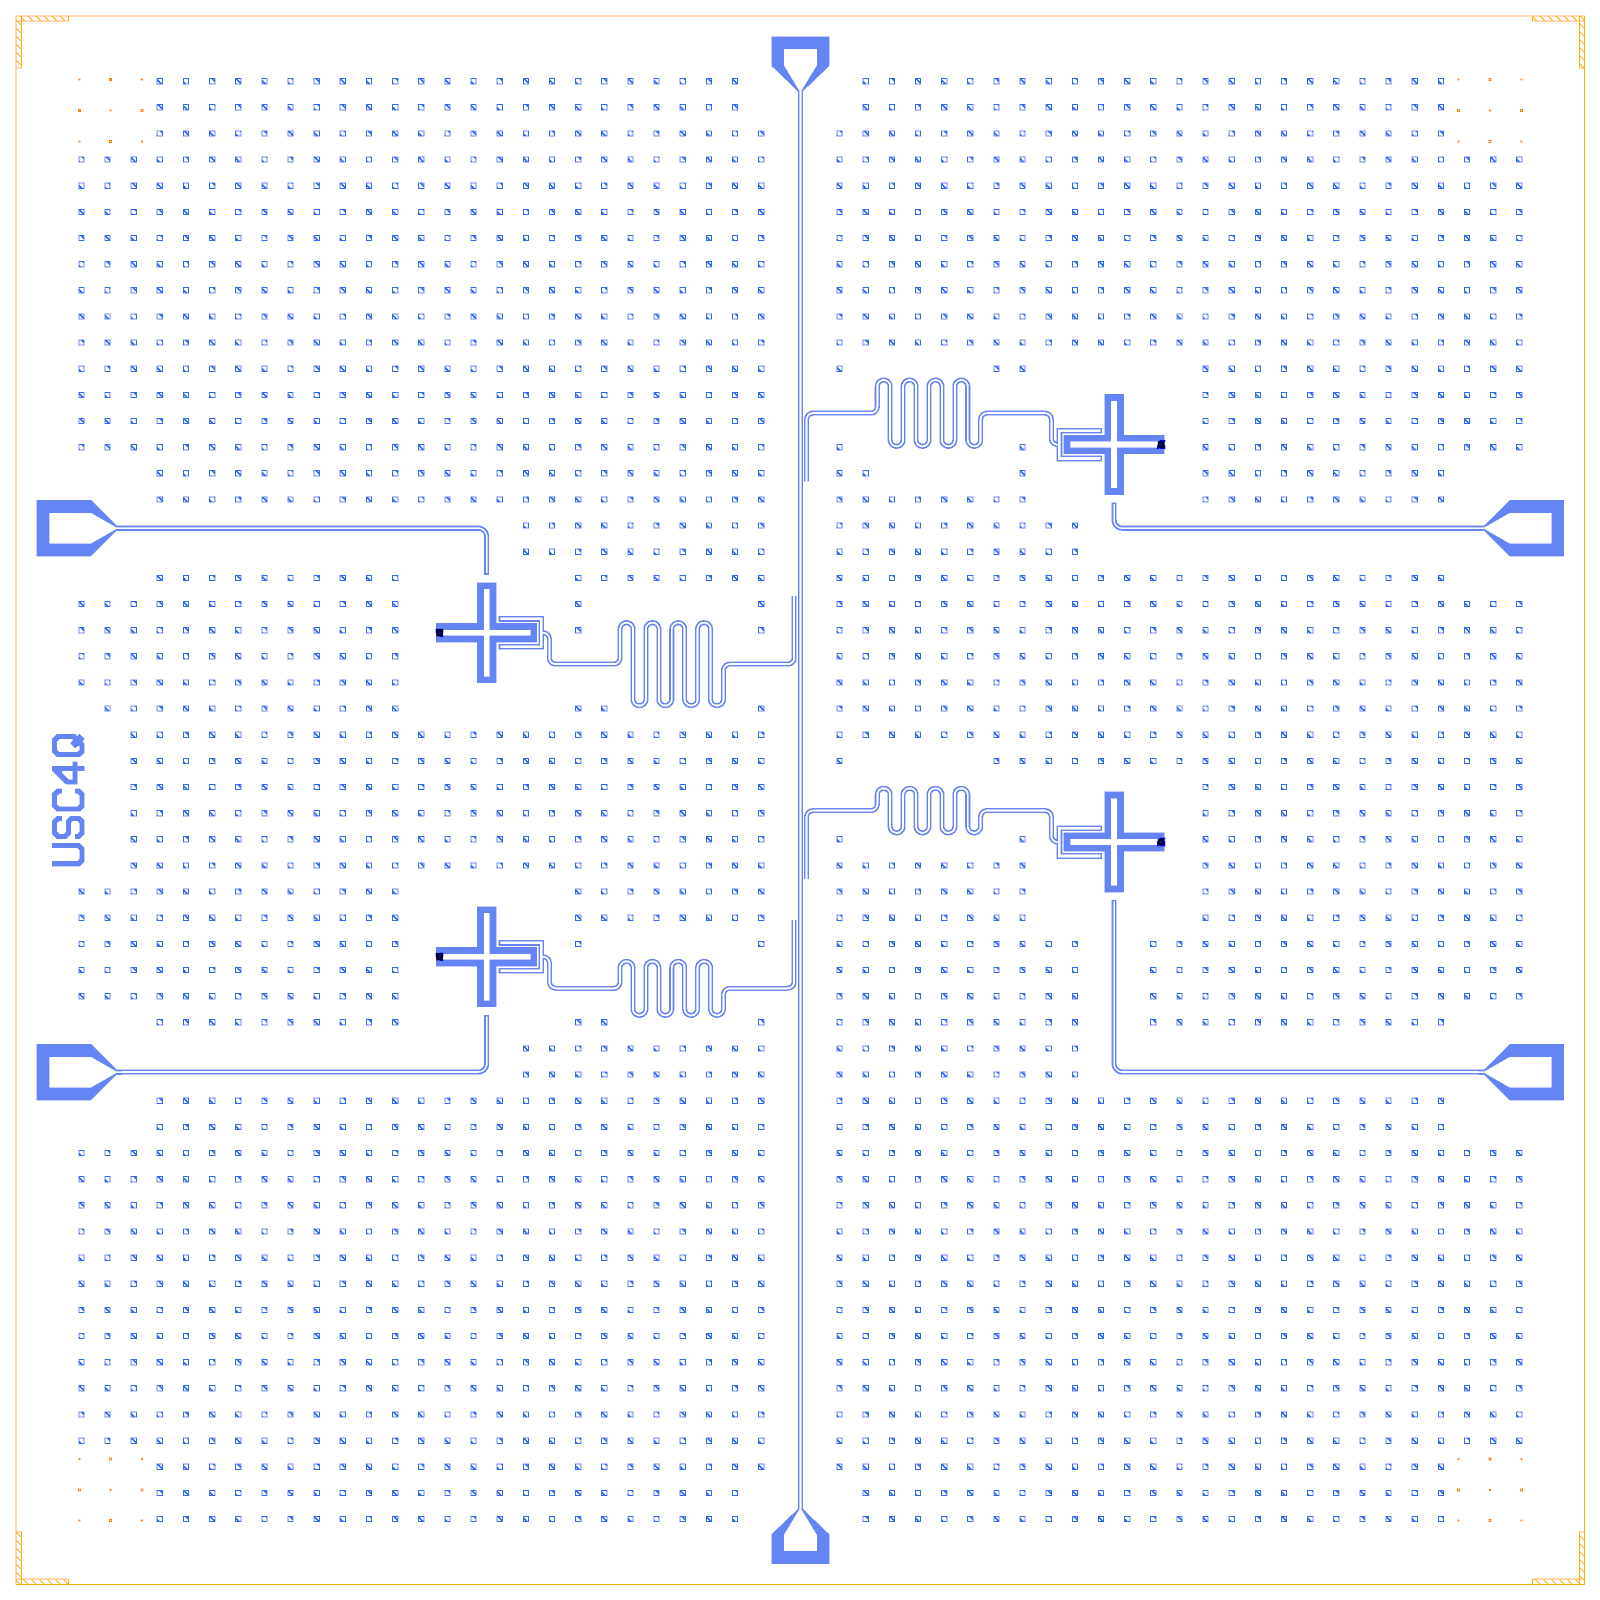

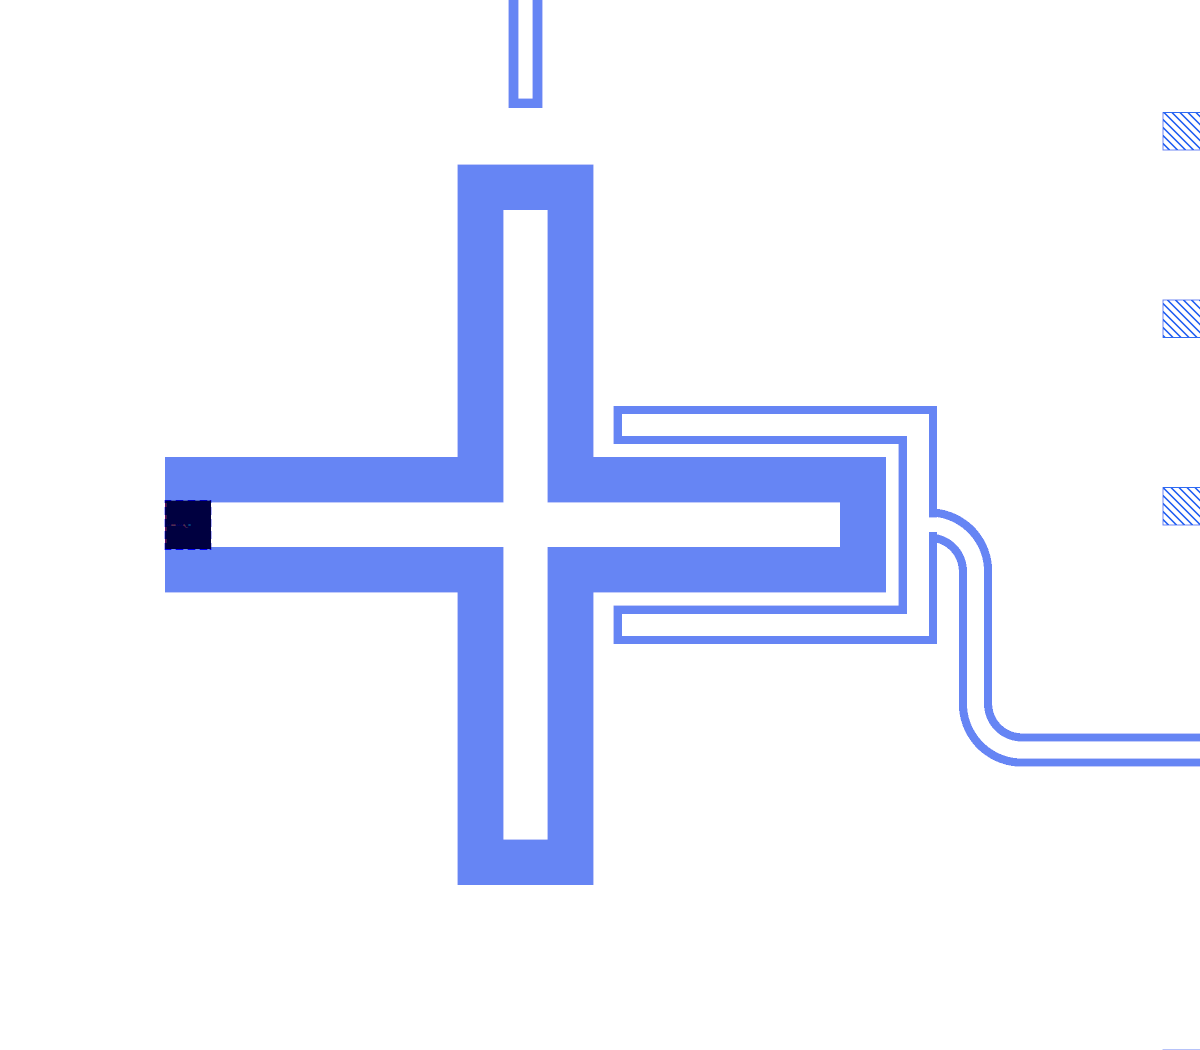

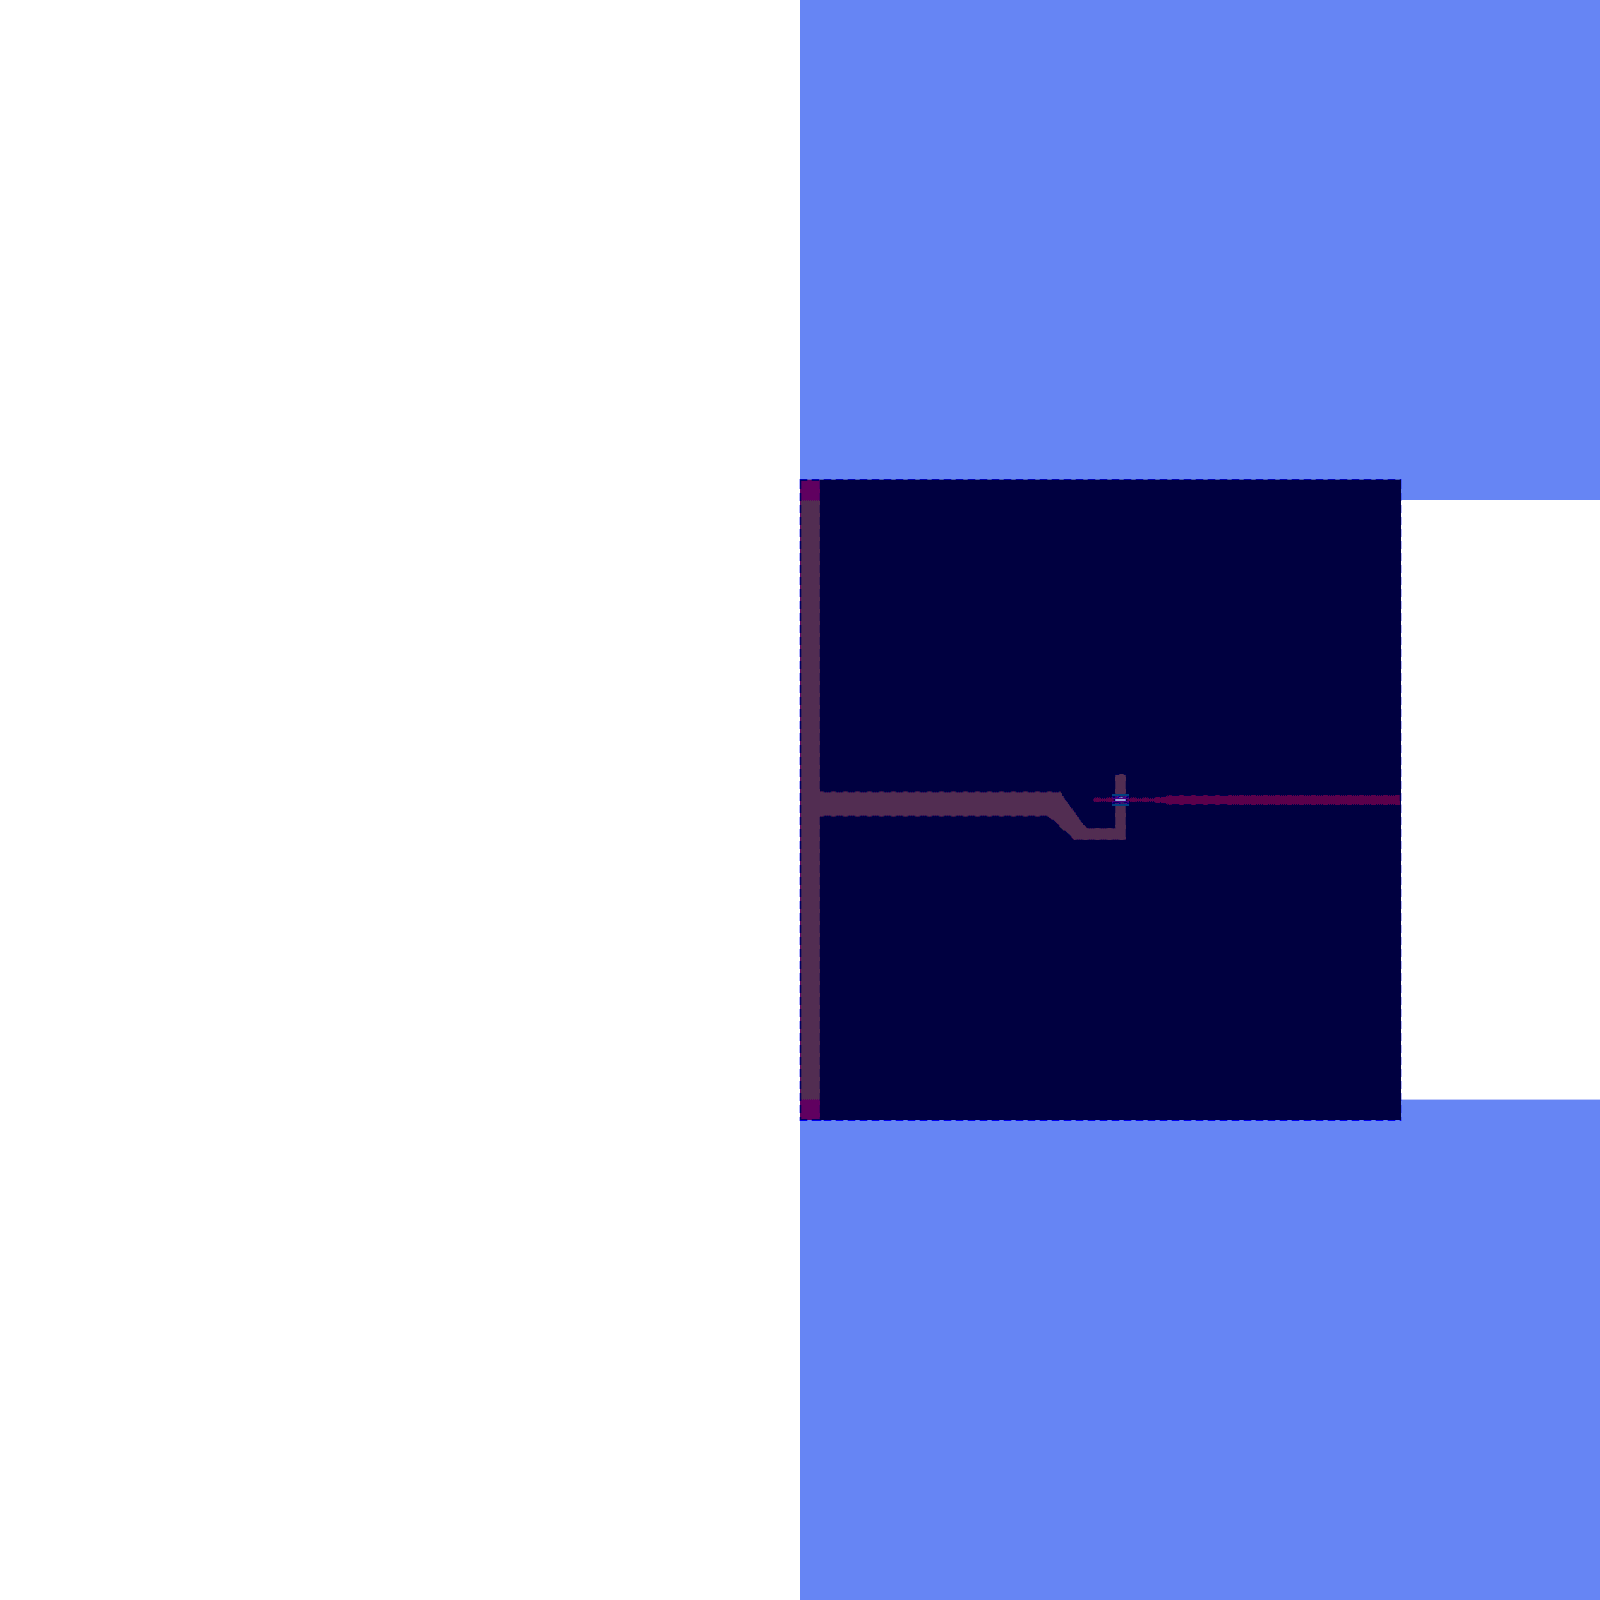

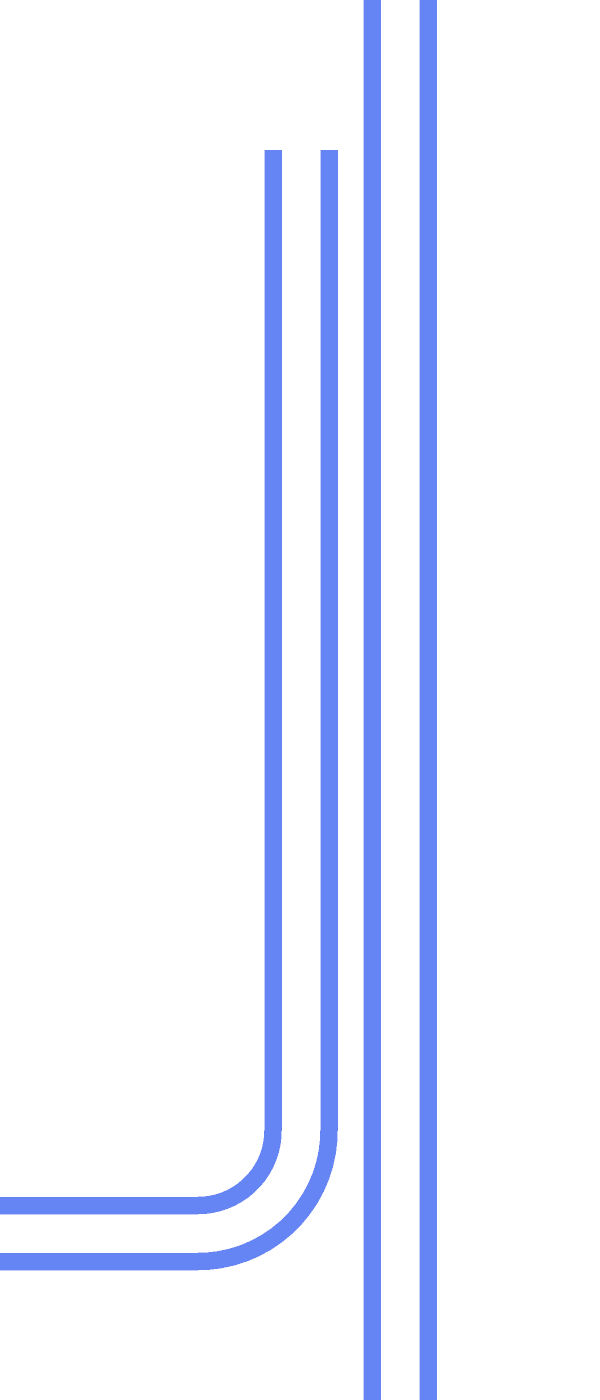

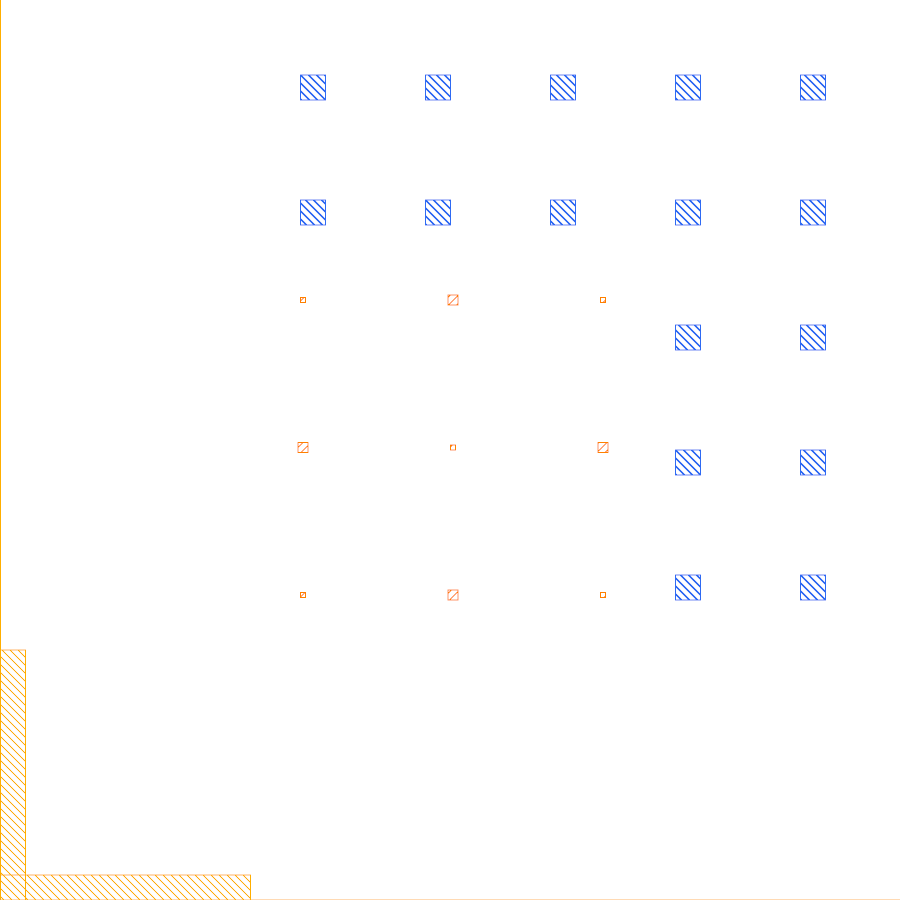

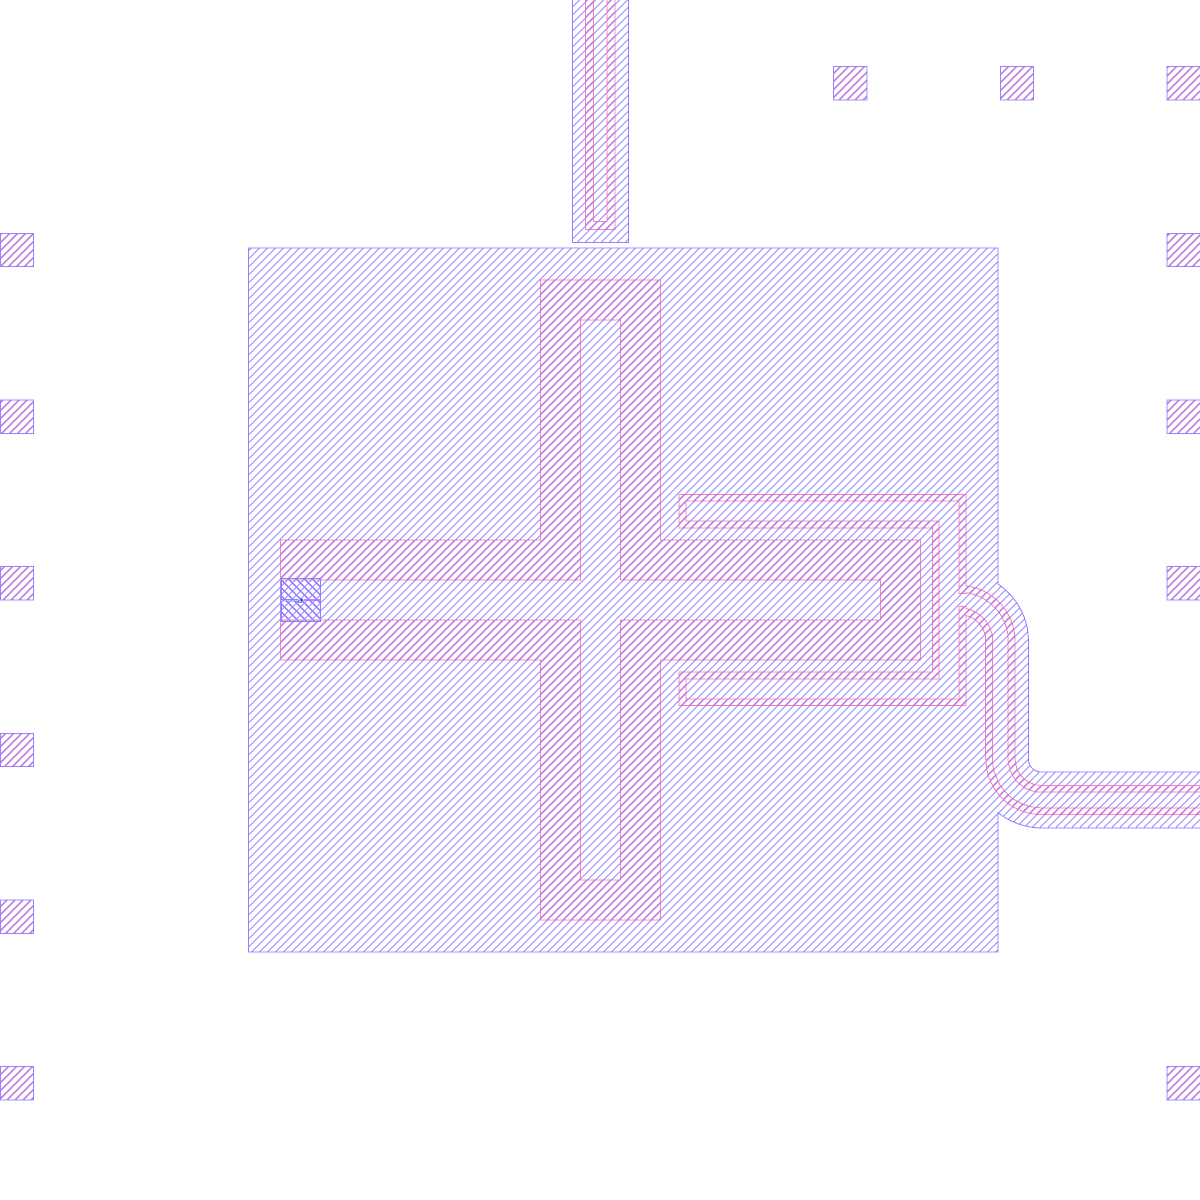

In [18]:
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip.png", size=(1600, 1600))
qx, qy = X0 - 1500, Y0 + 800
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_q1.png", box=(qx - 350, qy - 350, qx + 450, qy + 350), size=(1200, 1050), width=450)
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_jj.png", box=(qx - 280, qy - 40, qx - 200, qy + 40), width=300)
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_coupler.png", box=(X0 - 120, Y0 + 600, X0 + 60, Y0 + 1020), size=(600, 1400), width=220)
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_frame.png", box=(-1250, -1250, -350, -350), size=(900, 900), width=300)
snap_file(Path("build") / "tutorial_5_fab_ready_chip_fab.oas", OUT / "tutorial_5_fab_ready_chip_fab_q1.png",
          box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(1200, 1200), width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | the four `TransmonCross` qubits with the source's options and positions; the readout lengths 4570 / 3930 / 3460 / 3100 µm with the 325 µm coupled sections at the source's centres; the feedline and charge-line paths; the targets; the source's cheese rule |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; the six pads 100 µm from the die edge (longer feedline and charge lines); sapphire instead of silicon; Quantcore trilayer junctions sized for 4.05 GHz instead of the database's Dolan junction |
| **assumed** | the claw gap and ground spacing; the resonator gap 5.1 µm |
| **PDK design warnings** | `pdk_rn` × 4 (R_n 90 kΩ) and `pdk_fq` × 4 (target 3.7 GHz): flagged, not retuned |
| **FEM** | 8 jobs exported (`build/jobs/tutorial_5_fab_ready_chip_*`: Q3D + eigenmode per qubit), not solved here |